# 03 — Transfer learning and fine-tuning (Persian BERT, two heads)

**Question:** does fine-tuning a pretrained Persian encoder on the Digikala training split beat the TF-IDF + logistic regression baseline from notebook 02, on the same product-grouped split and the same test sample?

This notebook **reads the saved results** of the fine-tuning run (`ft_200k`); it does **not** retrain anything (training took about 4 hours on a 4 GB GPU).
The training code is `src/finetune_transformer.py` and the test evaluation is `src/evaluate_test.py`.

Rules followed: only the pretrained weights come from outside the project; all task data follow the project split (`SPLIT_SEED = 2026`); a row with a missing target is masked **only for that head's loss**;
the test sample is evaluated once per model (section 8).

**Provenance labels used below:** numbers *read from files* are computed when you run the cell. Numbers marked *copied* come from earlier printed output (they are not recomputed here).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
REPORTS = ROOT / "reports"
TEST = REPORTS / "test_results"
REC = ["no_idea", "not_recommended", "recommended"]
BAND = ["low", "medium", "high"]
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)

def load_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

H = load_json(REPORTS / "ft_200k_history.json")        # supervised fine-tuning run
CTRL = load_json(REPORTS / "ctrl_200k_history.json")   # control run (continued training, labeled rows only)
VAL = load_json(REPORTS / "ft_200k_eval_validation.json")
CMP = load_json(TEST / "comparison.json")
T_BASE = load_json(TEST / "tfidf_baseline.json")
T_TRF = load_json(TEST / "transformer_supervised.json")
print("project root:", ROOT)
print("evaluations in the run:", len(H["evals"]), "| logged loss points:", len(H["train_loss"]))

project root: /run/media/elahe/New Volume/maktab/145/digikala-review-classifier
evaluations in the run: 14 | logged loss points: 125


## 1. Model choice

| item | choice |
|---|---|
| checkpoint | `HooshvareLab/bert-fa-base-uncased` (ParsBERT v2, uncased) |
| tokenizer | the WordPiece tokenizer of the same checkpoint, vocabulary of about 100,000 pieces |
| licence | **Apache-2.0** (shown on the model's page on the Hugging Face Hub; checked on 7 November 2026 — please re-check the live page before submitting) |
| reason | the vocabulary is built for Persian only, so Persian words are split into few pieces (short sequences, faster training); BERT-base size is large enough to be strong, and small enough to fit in 4 GB of GPU memory when the word-embedding table is frozen |
| alternative considered | `xlm-roberta-base` (multilingual, but its vocabulary is much larger and mostly not Persian, which costs memory for the embedding table) — **not trained**, so no empirical comparison is claimed |

Architecture: one shared encoder, two linear heads (recommendation status and rating band) on the `[CLS]` vector, dropout 0.1.
The loss is the sum of two cross-entropy terms with balanced class weights computed from labeled training rows only; a missing target is masked with `-100` for that head only.

In [2]:
a = H["args"]
params = pd.DataFrame([
    {"quantity": "total parameters", "value": f'{H["total_params"]:,}'},
    {"quantity": "trainable parameters", "value": f'{H["trainable_params"]:,}'},
    {"quantity": "frozen parameters", "value": f'{H["total_params"] - H["trainable_params"]:,}'},
    {"quantity": "share trainable", "value": f'{H["trainable_params"] / H["total_params"]:.1%}'},
    {"quantity": "what is frozen", "value": "word-embedding table only (freeze_embeddings = %s); all encoder blocks and both heads are trained" % a["freeze_embeddings"]},
]).set_index("quantity")
params

,value
quantity,
total parameters,"162,845,958"
trainable parameters,"86,045,958"
frozen parameters,"76,800,000"
share trainable,52.8%
what is frozen,word-embedding table only (freeze_embeddings = True); all encoder blocks and both heads are trained


## 2. Tokenizer and maximum sequence length

Token lengths were measured earlier on a random sample of 20,000 training reviews (`04_transformer_prep.ipynb`).
**Copied, not recomputed here:**

| statistic | tokens |
|---|---|
| median | 9 |
| 75th percentile | 15 |
| 90th percentile | 27 |
| 95th percentile | 38 |
| 99th percentile | 71 |
| share longer than 64 tokens | 1.34% |
| share longer than 128 tokens | 0.16% |

Most reviews are very short, so `max_length = 64` keeps 98.66% of reviews untruncated while keeping batches cheap.
Going to 128 would save only about 1.2% more reviews at a much higher cost per batch. Truncated reviews lose their ending; this is a known limit (section 10).

## 3. Training setup

All values in the table are read from the saved run (`ft_200k_history.json`, field `args`) or computed from its evaluation list.

In [3]:
evals = H["evals"]
best = max(evals, key=lambda e: e["mean_macro_f1"])
steps_total = H["train_loss"][-1]["step"]
setup = pd.DataFrame([
    ("training rows (random subset of train_supervised, seed %d)" % a["seed"], f'{a["train_rows"]:,}'),
    ("validation rows used for selection (random sample)", f'{a["val_rows"]:,}'),
    ("epochs / optimizer steps (last logged step)", f'{a["epochs"]} / {steps_total:,}'),
    ("batch size / gradient accumulation", f'{a["batch_size"]} / {a["grad_accum"]}'),
    ("learning rate: encoder / heads", f'{a["lr_encoder"]:g} / {a["lr_head"]:g}'),
    ("weight decay (not on bias and LayerNorm)", a["weight_decay"]),
    ("schedule", f'linear warm-up {a["warmup_ratio"]:.0%}, then linear decay; gradient clipping 1.0'),
    ("max_length", a["max_length"]),
    ("mixed precision (fp16)", "no" if a["no_amp"] else "yes"),
    ("length-bucketed batches (chunk size)", a["bucket_chunk"]),
    ("evaluation every (steps)", a["eval_every_steps"]),
    ("rest after each checkpoint (minutes)", a["rest_minutes"]),
    ("early-stopping patience (evaluations)", a["patience"]),
    ("selected checkpoint", f'step {best["step"]} (highest mean of the two macro-F1 values: {best["mean_macro_f1"]:.4f})'),
    ("training time (minutes)", H["minutes"]),
    ("peak GPU memory (GB)", H["peak_gpu_gb"]),
], columns=["setting", "value"]).set_index("setting")
setup

,value
setting,
"training rows (random subset of train_supervised, seed 2026)","200,000"
validation rows used for selection (random sample),"10,000"
epochs / optimizer steps (last logged step),"2 / 12,500"
batch size / gradient accumulation,32 / 1
learning rate: encoder / heads,2e-05 / 0.001
weight decay (not on bias and LayerNorm),0.01
schedule,"linear warm-up 6%, then linear decay; gradient clipping 1.0"
max_length,64
mixed precision (fp16),yes


**Selection rule.** Every `eval_every_steps` steps the model is scored on a 10,000-row validation sample; the checkpoint with the highest **mean of the two macro-F1 values** (recommendation and band) is kept as `best.pt`.
Training stops early if this score does not improve for `patience` evaluations.

## 4. Training and validation curves

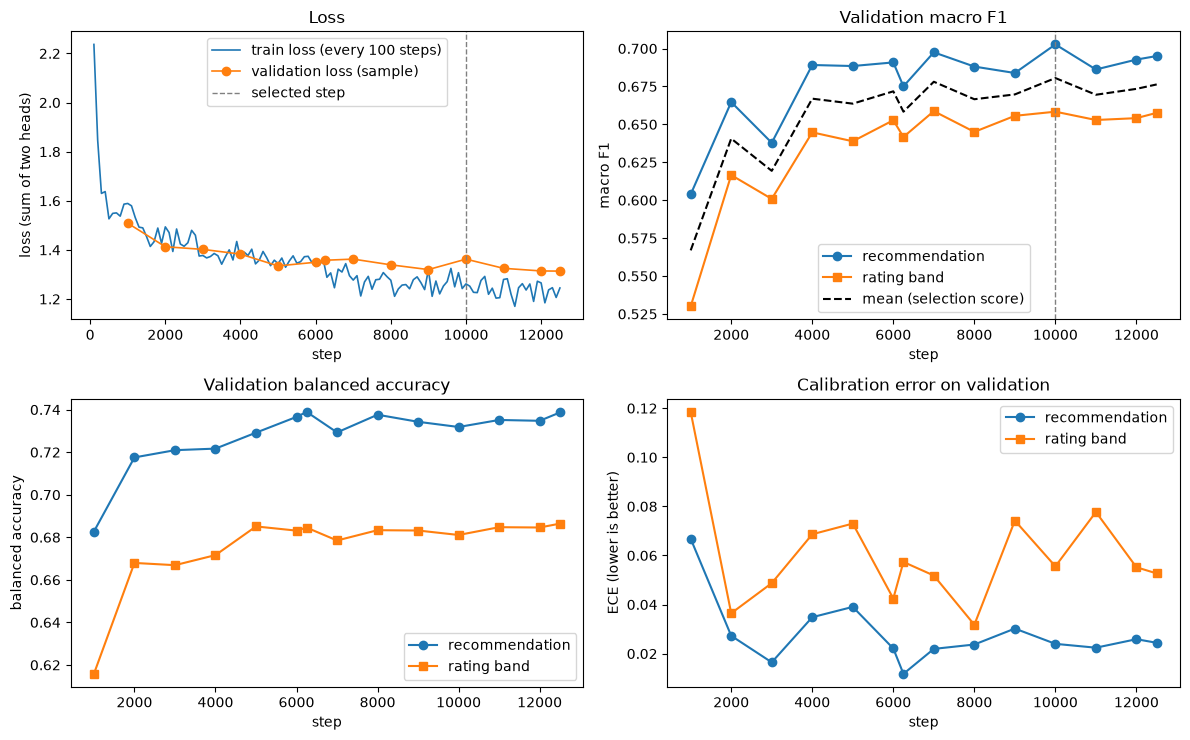

macro F1 recommendation: first eval (step 1000) 0.6039 -> best 0.7027 (step 10000) -> last eval 0.6951
macro F1 rating band   : first eval 0.5300 -> best 0.6584 -> last eval 0.6576


In [4]:
steps = [e["step"] for e in evals]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))

ax = axes[0, 0]
tl = H["train_loss"]
ax.plot([p["step"] for p in tl], [p["loss"] for p in tl], lw=1.2, label="train loss (every %d steps)" % a["log_every"])
ax.plot(steps, [e["val_loss"] for e in evals], "o-", lw=1.2, label="validation loss (sample)")
ax.axvline(best["step"], color="grey", ls="--", lw=1, label="selected step")
ax.set_xlabel("step"); ax.set_ylabel("loss (sum of two heads)"); ax.set_title("Loss"); ax.legend()

ax = axes[0, 1]
ax.plot(steps, [e["rec"]["macro_f1"] for e in evals], "o-", label="recommendation")
ax.plot(steps, [e["band"]["macro_f1"] for e in evals], "s-", label="rating band")
ax.plot(steps, [e["mean_macro_f1"] for e in evals], "k--", label="mean (selection score)")
ax.axvline(best["step"], color="grey", ls="--", lw=1)
ax.set_xlabel("step"); ax.set_ylabel("macro F1"); ax.set_title("Validation macro F1"); ax.legend()

ax = axes[1, 0]
ax.plot(steps, [e["rec"]["balanced_accuracy"] for e in evals], "o-", label="recommendation")
ax.plot(steps, [e["band"]["balanced_accuracy"] for e in evals], "s-", label="rating band")
ax.set_xlabel("step"); ax.set_ylabel("balanced accuracy"); ax.set_title("Validation balanced accuracy"); ax.legend()

ax = axes[1, 1]
ax.plot(steps, [e["rec"]["ece"] for e in evals], "o-", label="recommendation")
ax.plot(steps, [e["band"]["ece"] for e in evals], "s-", label="rating band")
ax.set_xlabel("step"); ax.set_ylabel("ECE (lower is better)"); ax.set_title("Calibration error on validation"); ax.legend()

plt.tight_layout(); plt.show()

first, last = evals[0], evals[-1]
print(f'macro F1 recommendation: first eval (step {first["step"]}) {first["rec"]["macro_f1"]:.4f} -> best {best["rec"]["macro_f1"]:.4f} (step {best["step"]}) -> last eval {last["rec"]["macro_f1"]:.4f}')
print(f'macro F1 rating band   : first eval {first["band"]["macro_f1"]:.4f} -> best {best["band"]["macro_f1"]:.4f} -> last eval {last["band"]["macro_f1"]:.4f}')

**Reading the curves.** Look at three things: (1) how quickly the macro F1 rises in the first evaluations, (2) whether later evaluations keep rising or only move up and down, and (3) whether the validation loss keeps falling.
The validation sample has 10,000 rows and the rare class `no_idea` has few of them, so differences of about 0.01 between neighbouring evaluations are within normal noise; the selected step is therefore **not** a precisely located optimum.

## 5. Evidence about overfitting and instability

Two sources, both read from files:

1. the supervised run itself (section 4: does the validation loss stop improving while the training loss falls?);
2. the **control run** `ctrl_200k`: it starts from the selected checkpoint and trains **two more epochs on the same kind of labeled data** with the same settings, so it shows what happens when training simply continues.

,"train loss, mean of first 10 points","train loss, mean of last 10 points",validation loss at the starting checkpoint,"validation loss, first eval","validation loss, last eval",best validation mean macro F1
run,,,,,,
supervised run (ft_200k),1.6690,1.2345,NaN,1.5088,1.3136,0.6805
"control run (ctrl_200k, continued)",1.2207,1.1551,1.3623,1.5037,1.4020,0.6786


End of training: training loss  supervised 1.234 vs control 1.155  (control lower by 0.079)
End of training: validation loss supervised 1.314 vs control 1.402  (control higher by 0.088)
Validation loss at the checkpoint the control run started from: 1.362; its first evaluation: 1.504
Best validation mean macro F1: control minus supervised = -0.0020


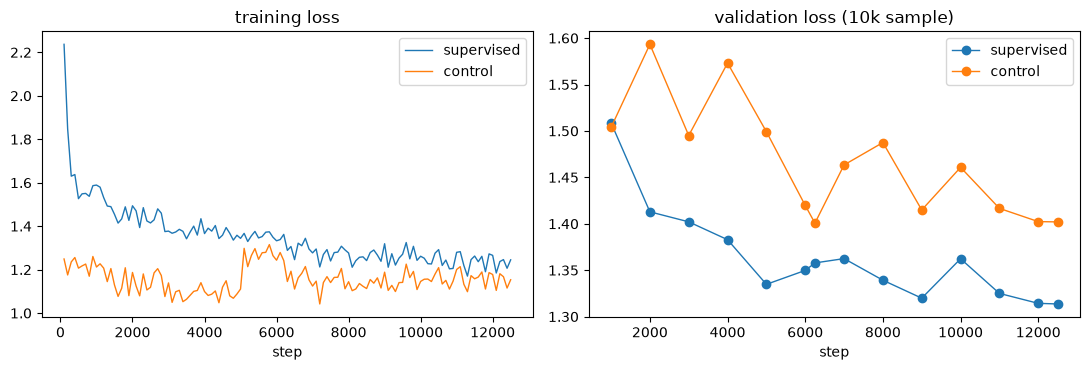

In [5]:
def smooth_mean(points, k):
    vals = [p["loss"] for p in points]
    return float(np.mean(vals[:k])), float(np.mean(vals[-k:]))

k = 10
start_val_loss = best["val_loss"]   # the control run starts from the selected checkpoint of the supervised run
rows = []
for name, run, start in (("supervised run (ft_200k)", H, None), ("control run (ctrl_200k, continued)", CTRL, start_val_loss)):
    t0, t1 = smooth_mean(run["train_loss"], k)
    rows.append({"run": name,
                 f"train loss, mean of first {k} points": t0,
                 f"train loss, mean of last {k} points": t1,
                 "validation loss at the starting checkpoint": start,
                 "validation loss, first eval": run["evals"][0]["val_loss"],
                 "validation loss, last eval": run["evals"][-1]["val_loss"],
                 "best validation mean macro F1": max(e["mean_macro_f1"] for e in run["evals"])})
over = pd.DataFrame(rows).set_index("run")
display(over.round(4))

sup_t = over.iloc[0, 1]; ctl_t = over.iloc[1, 1]
sup_v = over.iloc[0, 4]; ctl_v = over.iloc[1, 4]
print(f"End of training: training loss  supervised {sup_t:.3f} vs control {ctl_t:.3f}  (control lower by {sup_t - ctl_t:.3f})")
print(f"End of training: validation loss supervised {sup_v:.3f} vs control {ctl_v:.3f}  (control higher by {ctl_v - sup_v:.3f})")
print(f"Validation loss at the checkpoint the control run started from: {start_val_loss:.3f}; its first evaluation: {CTRL['evals'][0]['val_loss']:.3f}")
d_f1 = over.iloc[1, 5] - over.iloc[0, 5]
print(f"Best validation mean macro F1: control minus supervised = {d_f1:+.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for run, name in ((H, "supervised"), (CTRL, "control")):
    ax[0].plot([p["step"] for p in run["train_loss"]], [p["loss"] for p in run["train_loss"]], lw=1, label=name)
    ax[1].plot([e["step"] for e in run["evals"]], [e["val_loss"] for e in run["evals"]], "o-", lw=1, label=name)
ax[0].set_title("training loss"); ax[1].set_title("validation loss (10k sample)")
for x in ax: x.set_xlabel("step"); x.legend()
plt.tight_layout(); plt.show()

**How to read this.** The control run continues training the selected checkpoint on the same kind of labeled data.
Compare it with the supervised run at the **end** of training and with its own **starting point** (the validation loss of the selected checkpoint, printed above).

* If the control run reaches a **lower training loss** but a **higher validation loss** than the supervised run, the gap between training and validation has grown: this is the usual sign of starting to overfit.
* If, at the same time, the best validation macro F1 does **not** improve, then the extra training bought no better predictions, only a better fit to the training rows.
* Two other explanations cannot be excluded with these files: the continued run restarts the learning-rate schedule (a new warm-up can first make the loss jump up and then recover), and the validation loss is measured on a 10,000-row sample with visible noise between neighbouring evaluations.
  Validation loss is also not the same thing as macro F1: the loss can rise because the probabilities become over-confident, while the predicted classes change little.

So the careful claim is: *more training on the same data gave no better macro F1 and a worse validation loss, which is consistent with mild overfitting or over-confidence; it is not proof of it.*
Limits: one training run per setting (no repeated seeds), so run-to-run variation is unknown.

## 6. Training speed: what was tried (notes, not computed here)

**Copied from the work log, not recomputed:** the first version of the training loop ran at about 12 samples per second; with **length-bucketed batches** (`--bucket-chunk 50`: sort reviews by length inside chunks of 50 batches, then shuffle the batches) it ran at about 35 samples per second.
The reason is that most reviews are very short (median 9 tokens), so with random batches almost every batch is padded up to its longest review. Bucketing puts reviews of similar length together, so far fewer padding tokens are processed.
GPU memory use and temperature were checked and were **not** the cause of the slowness. A simulation estimated about 50 versus 13 padded tokens per review; this is an estimate, not a measurement of the final run.

## 7. Validation result of the selected checkpoint

Evaluated on a 100,000-row validation sample (a larger and different sample than the 10,000 rows used for selection); the file is `ft_200k_eval_validation.json`.

In [6]:
def head_row(m):
    r = {"rows": m["n"], "accuracy": m["accuracy"], "balanced accuracy": m["balanced_accuracy"],
         "macro precision": m["macro_precision"], "macro recall": m["macro_recall"], "macro F1": m["macro_f1"], "ECE": m["ece"]}
    if "ordinal_distance_error" in m:
        r.update({"ordinal distance error": m["ordinal_distance_error"], "quadratic weighted kappa": m["quadratic_weighted_kappa"]})
    return r

val_table = pd.DataFrame({"recommendation": head_row(VAL["rec"]), "rating band": head_row(VAL["band"])})
val_table.round(4)

,recommendation,rating band
rows,85327.0000,91279.0000
accuracy,0.8435,0.7539
balanced accuracy,0.7260,0.6840
macro precision,0.6698,0.6403
macro recall,0.7260,0.6840
macro F1,0.6942,0.6592
ECE,0.0274,0.0597
ordinal distance error,NaN,0.2667
quadratic weighted kappa,NaN,0.6685


## 8. Final test result against the baseline

Both models were scored **once** on the same fixed random test sample (all rows of that sample use the same products-grouped test split, so no product appears in training).
Confidence intervals come from a paired bootstrap over test rows (`src/compare_test.py`, the number of draws and seed are printed below). They describe **test-sampling noise only**, not the variation between training runs.

In [7]:
print("bootstrap draws:", CMP["draws"], "| seed:", CMP["seed"])
MODELS = {"tfidf_baseline": "TF-IDF + logistic regression", "transformer_supervised": "fine-tuned Transformer"}

def ci_text(v):
    return f"{v[0]:.4f} [{v[1]:.4f}, {v[2]:.4f}]"

for head, label in (("rec", "recommendation"), ("band", "rating band")):
    rows = []
    for key, name in MODELS.items():
        m = CMP["models"][head][key]
        t = (T_BASE if key == "tfidf_baseline" else T_TRF)[head]
        rows.append({"model": name, "macro F1 [95% CI]": ci_text(m["macro_f1"]), "accuracy [95% CI]": ci_text(m["accuracy"]),
                     "balanced accuracy [95% CI]": ci_text(m["balanced_accuracy"]),
                     "macro precision": round(t["macro_precision"], 4), "macro recall": round(t["macro_recall"], 4), "ECE": round(t["ece"], 4)})
    print(f"===== {label} (test) =====")
    display(pd.DataFrame(rows).set_index("model"))

    pair = CMP["pairs"][head]["transformer_supervised - tfidf_baseline"]
    prow = []
    for metric in ("macro_f1", "accuracy", "balanced_accuracy"):
        d, lo, hi = pair[metric][:3]
        prow.append({"metric": metric, "difference (Transformer - baseline) [95% CI]": f"{d:+.4f} [{lo:+.4f}, {hi:+.4f}]",
                     "interval excludes 0": "yes" if (lo > 0 or hi < 0) else "no"})
    display(pd.DataFrame(prow).set_index("metric"))

bootstrap draws: 2000 | seed: 2026
===== recommendation (test) =====


,macro F1 [95% CI],accuracy [95% CI],balanced accuracy [95% CI],macro precision,macro recall,ECE
model,,,,,,
TF-IDF + logistic regression,"0.6728 [0.6687, 0.6769]","0.8073 [0.8045, 0.8100]","0.7316 [0.7271, 0.7363]",0.6425,0.7316,0.0287
fine-tuned Transformer,"0.6933 [0.6891, 0.6976]","0.8462 [0.8437, 0.8486]","0.7278 [0.7235, 0.7324]",0.6672,0.7278,0.0280


,difference (Transformer - baseline) [95% CI],interval excludes 0
metric,,
macro_f1,"+0.0204 [+0.0164, +0.0245]",yes
accuracy,"+0.0389 [+0.0367, +0.0412]",yes
balanced_accuracy,"-0.0038 [-0.0082, +0.0007]",no


===== rating band (test) =====


,macro F1 [95% CI],accuracy [95% CI],balanced accuracy [95% CI],macro precision,macro recall,ECE
model,,,,,,
TF-IDF + logistic regression,"0.6364 [0.6327, 0.6404]","0.7263 [0.7235, 0.7293]","0.6750 [0.6708, 0.6791]",0.6131,0.6750,0.0552
fine-tuned Transformer,"0.6584 [0.6548, 0.6624]","0.7571 [0.7544, 0.7600]","0.6826 [0.6787, 0.6867]",0.6399,0.6826,0.0630


,difference (Transformer - baseline) [95% CI],interval excludes 0
metric,,
macro_f1,"+0.0220 [+0.0189, +0.0252]",yes
accuracy,"+0.0307 [+0.0284, +0.0331]",yes
balanced_accuracy,"+0.0076 [+0.0042, +0.0109]",yes


### Per-class precision, recall and F1 (test)

In [8]:
for head, labels, label in (("rec", REC, "recommendation"), ("band", BAND, "rating band")):
    b = pd.DataFrame(T_BASE[head]["per_class"]).T[["precision", "recall", "f1", "support"]]
    t = pd.DataFrame(T_TRF[head]["per_class"]).T[["precision", "recall", "f1", "support"]]
    both = pd.concat({"TF-IDF baseline": b[["precision", "recall", "f1"]], "Transformer": t[["precision", "recall", "f1"]]}, axis=1)
    both[("", "support")] = t["support"].astype(int)
    print(f"===== {label} (test) =====")
    display(both.reindex(labels).round(3))

===== recommendation (test) =====


TF-IDF baseline               Transformer                      
                      precision recall     f1   precision recall     f1 support
no_idea                   0.345  0.583  0.433       0.409  0.477  0.441    9511
not_recommended           0.619  0.768  0.685       0.638  0.803  0.711    7922
recommended               0.964  0.843  0.900       0.954  0.903  0.928   67846

===== rating band (test) =====


TF-IDF baseline               Transformer                      
             precision recall     f1   precision recall     f1 support
low              0.573  0.757  0.652       0.623  0.759  0.684    9022
medium           0.375  0.482  0.422       0.411  0.453  0.431   17031
high             0.891  0.785  0.835       0.886  0.836  0.860   65525

### Confusion matrices (test)

Each cell shows the share of the true class (row-normalised) and the row count.

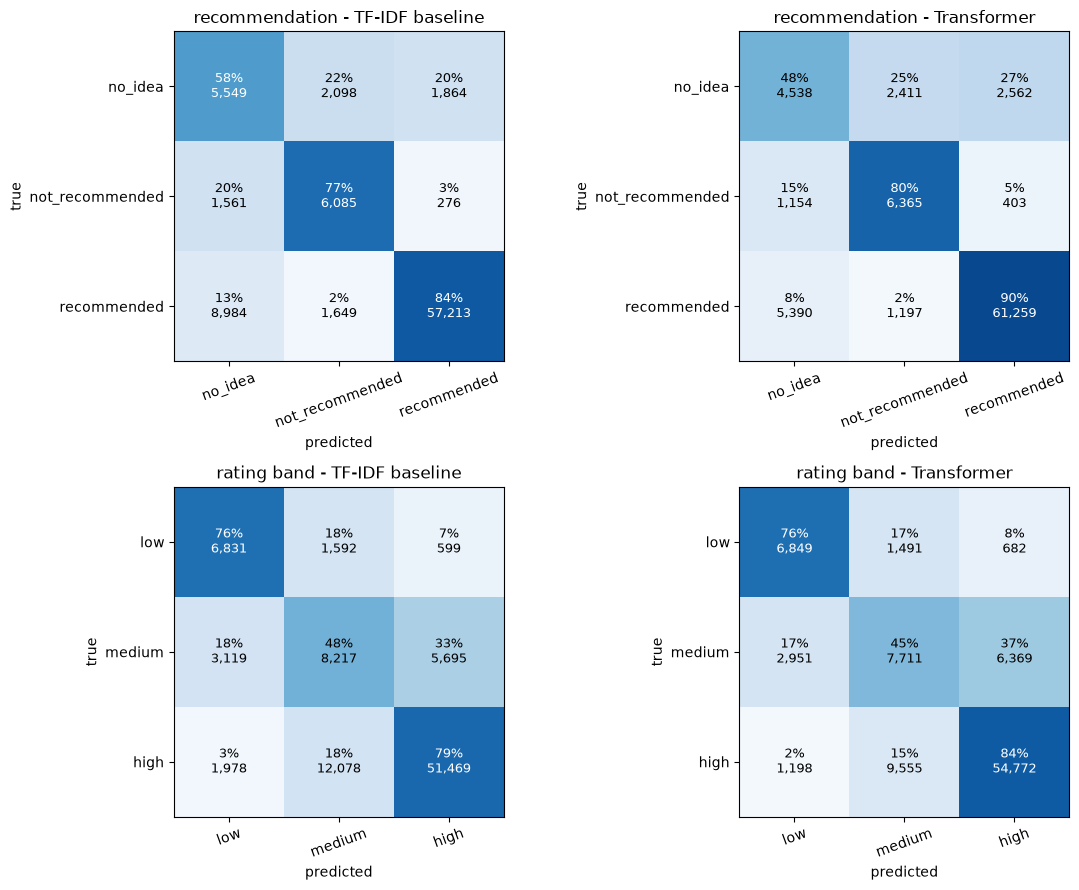

In [9]:
def plot_cm(ax, cm, labels, title):
    cm = np.array(cm, dtype=float)
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=20)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, f"{share[i, j]:.0%}\n{int(cm[i, j]):,}", ha="center", va="center",
                    color="white" if share[i, j] > 0.5 else "black", fontsize=9)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
plot_cm(axes[0, 0], T_BASE["rec"]["confusion_matrix"], REC, "recommendation - TF-IDF baseline")
plot_cm(axes[0, 1], T_TRF["rec"]["confusion_matrix"], REC, "recommendation - Transformer")
plot_cm(axes[1, 0], T_BASE["band"]["confusion_matrix"], BAND, "rating band - TF-IDF baseline")
plot_cm(axes[1, 1], T_TRF["band"]["confusion_matrix"], BAND, "rating band - Transformer")
plt.tight_layout(); plt.show()

### Calibration

ECE (expected calibration error) measures whether the predicted probabilities match how often the model is right: 0 is perfect. It matters here because a later step keeps pseudo-labels only above a probability of 0.90.

In [10]:
cal = pd.DataFrame({
    ("recommendation", "ECE"): {"TF-IDF baseline": T_BASE["rec"]["ece"], "Transformer": T_TRF["rec"]["ece"]},
    ("recommendation", "NLL"): {"TF-IDF baseline": T_BASE["rec"]["nll"], "Transformer": T_TRF["rec"]["nll"]},
    ("rating band", "ECE"): {"TF-IDF baseline": T_BASE["band"]["ece"], "Transformer": T_TRF["band"]["ece"]},
    ("rating band", "NLL"): {"TF-IDF baseline": T_BASE["band"]["nll"], "Transformer": T_TRF["band"]["nll"]},
})
cal.round(4)

recommendation         rating band        
                           ECE     NLL         ECE     NLL
TF-IDF baseline         0.0287  0.5030      0.0552  0.6695
Transformer             0.0280  0.4006      0.0630  0.6238

### Validation and test side by side

If selection had been optimistic, the test score of the Transformer would be clearly lower than its validation score.

In [11]:
vt = pd.DataFrame({
    "validation (100k sample)": {"recommendation macro F1": VAL["rec"]["macro_f1"], "rating band macro F1": VAL["band"]["macro_f1"]},
    "test (fixed sample)": {"recommendation macro F1": T_TRF["rec"]["macro_f1"], "rating band macro F1": T_TRF["band"]["macro_f1"]},
})
vt["difference (test - validation)"] = vt["test (fixed sample)"] - vt["validation (100k sample)"]
vt.round(4)

,validation (100k sample),test (fixed sample),difference (test - validation)
recommendation macro F1,0.6942,0.6933,-0.0010
rating band macro F1,0.6592,0.6584,-0.0007


## 9. Did fine-tuning improve the result?

The sentences below are produced **from the numbers above**, so they stay correct if a file changes.

In [12]:
def verdict(head, label):
    pair = CMP["pairs"][head]["transformer_supervised - tfidf_baseline"]
    out = []
    for metric, nice in (("macro_f1", "macro F1"), ("balanced_accuracy", "balanced accuracy"), ("accuracy", "accuracy")):
        d, lo, hi = pair[metric][:3]
        if lo > 0:
            word = "higher (interval above 0)"
        elif hi < 0:
            word = "lower (interval below 0)"
        else:
            word = "not clearly different (interval contains 0)"
        out.append(f"  - {nice}: {d:+.4f} [{lo:+.4f}, {hi:+.4f}] -> {word}")
    print(f"{label}:"); print("\n".join(out))

verdict("rec", "Recommendation head, Transformer minus baseline")
verdict("band", "Rating-band head, Transformer minus baseline")
t_rec = T_TRF["rec"]["per_class"]; b_rec = T_BASE["rec"]["per_class"]
print("\nRare class no_idea, F1: baseline %.3f -> Transformer %.3f" % (b_rec["no_idea"]["f1"], t_rec["no_idea"]["f1"]))

Recommendation head, Transformer minus baseline:
  - macro F1: +0.0204 [+0.0164, +0.0245] -> higher (interval above 0)
  - balanced accuracy: -0.0038 [-0.0082, +0.0007] -> not clearly different (interval contains 0)
  - accuracy: +0.0389 [+0.0367, +0.0412] -> higher (interval above 0)
Rating-band head, Transformer minus baseline:
  - macro F1: +0.0220 [+0.0189, +0.0252] -> higher (interval above 0)
  - balanced accuracy: +0.0076 [+0.0042, +0.0109] -> higher (interval above 0)
  - accuracy: +0.0307 [+0.0284, +0.0331] -> higher (interval above 0)

Rare class no_idea, F1: baseline 0.433 -> Transformer 0.441


**Interpretation (read together with the printed lines above).**

* The macro F1 comparison is the main criterion because the classes are imbalanced. Where the interval of the difference excludes 0, the Transformer is better on that head **on this test sample**.
* Accuracy and balanced accuracy can move in different directions: a model can win on accuracy by being better on the large class `recommended` while the rare classes improve less. Check the per-class table before claiming a general improvement.
* The rare class `no_idea` stays the hardest class for both models: its label is partly a matter of the reviewer's choice rather than of the words (see the label-noise check in `05_label_noise_check.ipynb`), so a ceiling on its F1 is expected.
* Fine-tuning used only 200,000 of about 3 million labeled training rows, and only for 2 epochs. The measured gain is therefore **a lower bound for what this encoder could achieve** with more data and time — but that is a statement about expectation, not something measured here.

## 10. Limitations

* **Subset of the data:** 200,000 training rows (about 6% of the labeled training rows) because of the 4 GB GPU and the time budget.
* **Frozen word-embedding table:** done to fit in memory; unfreezing might help, untested.
* **`max_length = 64`:** about 1.3% of reviews are truncated.
* **One seed, one run per model:** the bootstrap interval covers test-sampling noise only; training-run variation is unknown.
* **Model selection on a 10,000-row validation sample:** neighbouring evaluations differ by about 0.01, so the selected step is not a sharp optimum (validation and test agree closely, which argues against optimistic selection).
* **Test = a fixed random sample of 99,635 rows** of the test split, the same rows for every model; it is large, but it is not the whole split.
* **One checkpoint compared:** `xlm-roberta-base` and other encoders were not trained, so nothing is claimed about them.
* **Persian text issues:** colloquial negation and hedged phrases (for example "بد نیست") are still mis-handled in some cases; see the error analysis in the report.